# Northstar Care: complete the recovery, then reduce avoidable time
**Decision notebook · fictional case as of October 2, 2026 · operations through September 30.**

**Recommendation:** give General Care a WN7-specific recognition and recovery cue, short worked example, and branch practice; fix article discovery and system follow-up alongside coaching. Test in staggered cohorts before wider deployment. A generic empathy video alone cannot supply the missing operational path.

This notebook fulfills the user's request for cleaning, analysis, and a proposed solution. Attached requests for a Dana email, video, or interviewer note are case context, not additional user instructions. No messages are sent. All facts come from the packet; proposed actions and targets are labeled. Run all cells in order. See `02_monitoring.ipynb` for refreshable monitoring, `analysis_utils.py` for shared cleaning, and `README.md` for execution instructions.


In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / 'analysis_utils.py').exists() else Path.cwd() / 'northstar_analysis'
assert (ROOT / 'analysis_utils.py').exists(), 'Run from northstar_analysis or its parent.'
sys.path.insert(0, str(ROOT))
from analysis_utils import *
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 40)
D = load_data()
calls, ops = D['calls'], D['ops']


## 1. Data contract and cleaning
Daily operations and staffing are **full populations**; sampled calls are not demand. QA oversamples long/recovery-risk calls; feedback is voluntary and oversamples WN7 outreach. Neither produces population behavior or satisfaction rates.

The loader detects Excel headers below four title/note rows, trims strings, parses dates, converts metrics, validates keys and joins, and removes only consistent duplicate Call IDs. Missing product/reason values remain missing; no inferred eligibility or imputation. WN7 + WNM-7 product buckets identify WN7-containing contacts, not affected households or eligible serials. Source eligibility is retrospective: pre-release non-recovery is not a Guide failure.

AHT and its components are independently rounded to one decimal; a 0.15-minute tolerance accommodates the observed ±0.1-minute differences without rewriting source durations. Daily wait lacks a denominator definition: offered-weighted wait is explicitly a proxy. Occupancy is scheduled-hours weighted, also a proxy. AHT is answered-contact weighted; abandonment is total abandoned / total offered.


In [2]:
display(D['audit'])
missing = calls[['Product code','Reason code']].isna().sum().to_frame('missing_n')
missing['share'] = missing['missing_n'] / len(calls)
display(missing)
display(D['catalog_unmatched'])
print('Unmatched catalog rows:', D['catalog_unmatched']['sample_calls'].sum())
print('Duplicate export rows removed:', len(D['duplicate_rows']))
print('Operations range:', ops.Date.min().date(), 'to', ops.Date.max().date())
print('QA joined:',len(D['qa_joined']),'; feedback joined:',len(D['feedback_joined']))
export_clean(D)


,table,raw_rows,header_excel_row,missing_key,clean_rows,removed_rows
0,daily,366,5,0,366,0
1,calls,20028,5,0,20000,28
2,staff,366,5,0,366,0
3,catalog,250,5,0,250,0
4,qa,1600,5,0,1600,0
5,feedback,2200,5,0,2200,0


,missing_n,share
Product code,158,0.0079
Reason code,260,0.0130


,Product code,sample_calls
0,LC-63,80
1,SP-14,77
2,CM-32,76
3,LC-41,73
4,WNM-9,73
5,WN5,72
6,WNM-6,71
7,WN9,71
8,WNM-8,69
9,PL-19,67


Unmatched catalog rows: 1229
Duplicate export rows removed: 28
Operations range: 2026-04-01 to 2026-09-30
QA joined: 1600 ; feedback joined: 2200


**Additional data-quality finding:** the catalog omits several non-WN7 codes present in sampled calls. Retain them as other products; do not discard their calls or fabricate catalog descriptions. WN7 and WNM-7 are explicitly documented. The table above lists all unmatched codes. Sample missingness and catalog gaps limit granular product comparisons. Cleaned CSVs, duplicate removals, and source SHA-256 hashes are exported to `outputs/` for audit.


In [3]:
ops['Month'] = ops.Date.dt.to_period('M').astype(str)
monthly = ops.groupby(['Queue','Month']).apply(population_metrics, include_groups=False)
display(monthly.round(3))
monthly.to_csv(OUT/'monthly_population_metrics.csv')
gc = monthly.loc['General Care']
a, b = gc.loc['2026-08'], gc.loc['2026-09']
display(pd.DataFrame({'August':a,'September':b,'change':b-a}).round(3))


days   offered  answered  offered_per_day  AHT_min  \
Queue           Month                                                         
General Care    2026-04  30.0  646652.0  614759.0        21555.067    8.445   
                2026-05  31.0  672100.0  642142.0        21680.645    8.450   
                2026-06  30.0  654059.0  626230.0        21801.967    8.532   
                2026-07  31.0  679535.0  653723.0        21920.484    8.503   
                2026-08  31.0  685095.0  656610.0        22099.839    8.579   
                2026-09  30.0  812952.0  581596.0        27098.400   11.136   
Specialist Care 2026-04  30.0   33721.0   32541.0         1124.033    9.053   
                2026-05  31.0   36197.0   34932.0         1167.645    9.029   
                2026-06  30.0   36456.0   35183.0         1215.200    9.046   
                2026-07  31.0   39008.0   37642.0         1258.323    9.042   
                2026-08  31.0   40526.0   39089.0         1307.290    9.044   
                2026-09  30.0   53239.0   44636.0         1774.633    9.863   

                         wait_min_proxy  abandonment  WN7_contact_share  \
Queue           Month                                                     
General Care    2026-04           1.820        0.049              0.008   
                2026-05           1.803        0.045              0.008   
                2026-06           1.763        0.043              0.008   
                2026-07           1.655        0.038              0.008   
                2026-08           1.672        0.042              0.013   
                2026-09           4.354        0.285              0.303   
Specialist Care 2026-04           1.630        0.035              0.018   
                2026-05           1.687        0.035              0.018   
                2026-06           1.619        0.035              0.018   
                2026-07           1.696        0.035              0.018   
                2026-08           1.684        0.035              0.031   
                2026-09           2.584        0.162              0.492   

                         actual_planned  occupancy_proxy  
Queue           Month                                     
General Care    2026-04           0.938            0.764  
                2026-05           0.936            0.759  
                2026-06           0.939            0.755  
                2026-07           0.938            0.748  
                2026-08           0.941            0.742  
                2026-09           0.920            0.861  
Specialist Care 2026-04           0.920            0.671  
                2026-05           0.925            0.665  
                2026-06           0.925            0.662  
                2026-07           0.925            0.664  
                2026-08           0.932            0.664  
                2026-09           0.936            0.819

,August,September,change
days,31.000,30.000,-1.000
offered,685095.000,812952.000,127857.000
answered,656610.000,581596.000,-75014.000
offered_per_day,22099.839,27098.400,4998.561
AHT_min,8.579,11.136,2.557
wait_min_proxy,1.672,4.354,2.682
abandonment,0.042,0.285,0.243
WN7_contact_share,0.013,0.303,0.290
actual_planned,0.941,0.920,-0.021
occupancy_proxy,0.742,0.861,0.120


## 2. Queue pressure is a volume and handling problem
General Care offered contacts per day rose **22.6%**, from 22,100 in August to 27,098 in September. Answered-weighted AHT rose **8.58 → 11.14 minutes** (+29.8%). Abandonment rose **4.16% → 28.46%** (+24.30 percentage points). WN7-containing share of answered contacts rose **1.32% → 30.28%**, while actual/planned Guide coverage slipped **94.1% → 92.0%**.

These concurrent changes support addressing WN7 recovery and staffing, but do not identify how much population AHT is causally attributable to the defect. Tags are imperfect; there are no population durations by product or customer identifiers. More callers abandoning also changes the answered population. Do not multiply sampled call differences by full volume to claim savings.


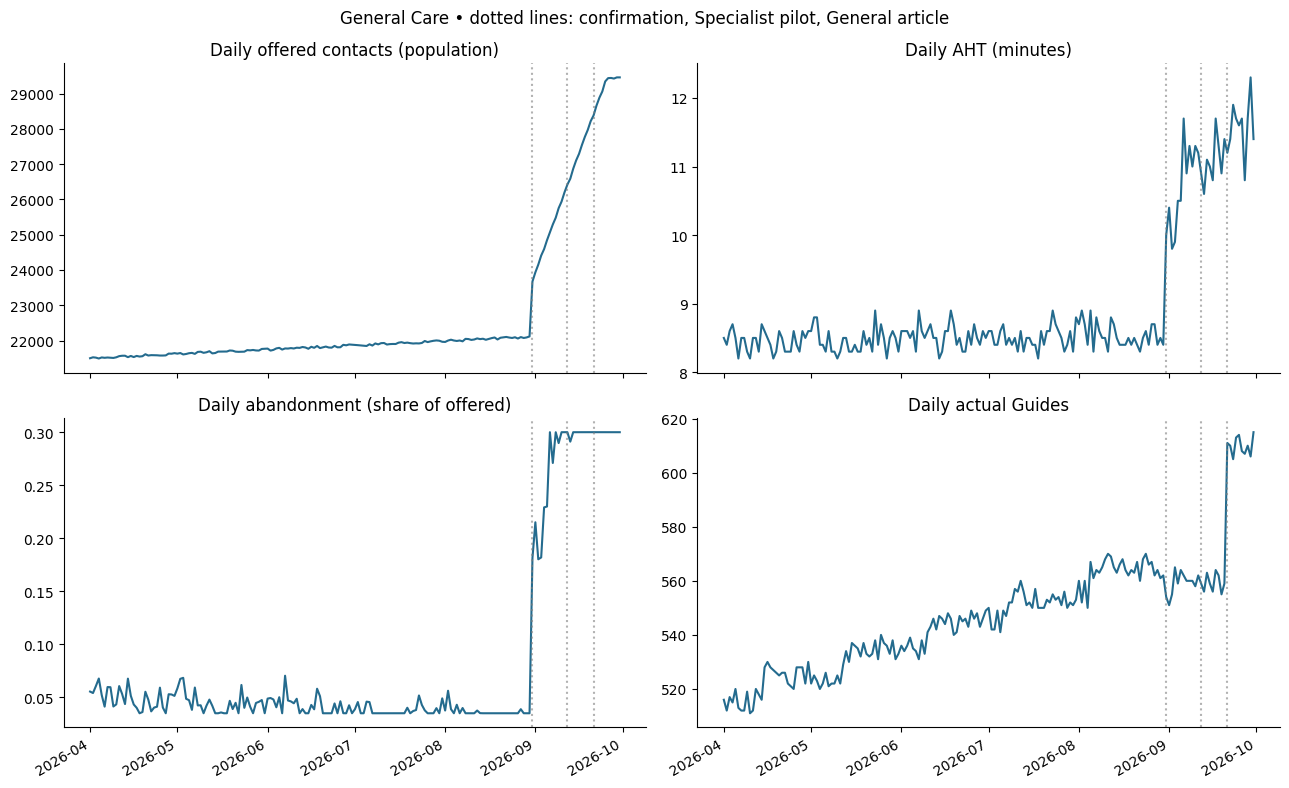

In [4]:
g = ops[ops.Queue.eq('General Care')].sort_values('Date')
fig, ax = plt.subplots(2, 2, figsize=(13,8), sharex=True)
for axis, field, title in zip(ax.flat,
 ['Offered contacts','Average handle minutes','Abandonment rate','Actual Guides'],
 ['Daily offered contacts (population)','Daily AHT (minutes)','Daily abandonment (share of offered)','Daily actual Guides']):
 axis.plot(g.Date,g[field],color='#246b8e');axis.set_title(title)
 for date in ['2026-08-31','2026-09-12','2026-09-21']:
  axis.axvline(pd.Timestamp(date),color='grey',ls=':',alpha=.6)
fig.suptitle('General Care • dotted lines: confirmation, Specialist pilot, General article')
fig.autofmt_xdate();fig.tight_layout();plt.show()


In [5]:
# Descriptive product segments, including missing codes; no sample expansion weights.
calls['Month'] = calls['Call date'].dt.to_period('M').astype(str)
segments = calls.groupby(['Queue','Month','Product segment'])['AHT minutes'].agg(n='size',mean='mean',median='median')
display(segments.loc[('General Care', ['2026-08','2026-09']), :].round(2))
components = ops.groupby(['Queue','Month']).apply(
 lambda x: pd.Series({k:np.average(x[k],weights=x['Answered contacts']) for k in
 ['Average talk minutes','Average hold minutes','Average wrap minutes']}),include_groups=False)
display(components.loc[('General Care', ['2026-08','2026-09']),:].round(2))


n   mean  median
Queue        Month   Product segment                     
General Care 2026-08 Other products   3139   8.53    8.20
                     Unknown            28   8.65    8.20
                     WN7-containing     49  11.74    8.80
             2026-09 Other products   2054   8.47    8.15
                     Unknown            15  10.82    8.20
                     WN7-containing    882  17.25   17.10

Average talk minutes  Average hold minutes  \
Queue        Month                                                 
General Care 2026-08                  6.09                  1.37   
             2026-09                  7.90                  1.79   

                      Average wrap minutes  
Queue        Month                          
General Care 2026-08                  1.11  
             2026-09                  1.45

## 3. Availability is not adoption or successful recovery
Chronology matters: August 31 issue confirmed; September 10 offer approved; September 12 Specialist pilot starts; September 21 General Care article becomes available. The September 28 thread confirms a weekly roundup, **no separate incident alert or scheduled shift briefing**, and no readership evidence. General article publication therefore does not prove exposure or competence.

`Case_info.md`, BH-4419 / PO-117: verify serial, follow the eligible/not-eligible/unavailable branch, and complete **both** replacement and Plus. Product model alone is insufficient. `meetings.md`, September 21 and 24: generic search can return the old restart flow; pending credit and incomplete recaps persist. These qualitative observations explain plausible mechanisms, not prevalence.


eligible_n  serial_n  \
Queue           Phase                                             
General Care    Approved; before pilot           38.0      19.0   
                Before approval                 141.0       0.0   
                General article available       204.0     159.0   
                Specialist pilot only            92.0      46.0   
Specialist Care Approved; before pilot            0.0       0.0   
                Before approval                   0.0       0.0   
                General article available        77.0      77.0   
                Specialist pilot only           116.0     116.0   

                                           replacement_n  plus_n  complete_n  \
Queue           Phase                                                          
General Care    Approved; before pilot               0.0     0.0         0.0   
                Before approval                      0.0     0.0         0.0   
                General article available           89.0    76.0        76.0   
                Specialist pilot only                0.0     0.0         0.0   
Specialist Care Approved; before pilot               0.0     0.0         0.0   
                Before approval                      0.0     0.0         0.0   
                General article available           77.0    63.0        63.0   
                Specialist pilot only              116.0   100.0       100.0   

                                           complete_rate  incomplete_n  
Queue           Phase                                                   
General Care    Approved; before pilot             0.000          38.0  
                Before approval                    0.000         141.0  
                General article available          0.373         128.0  
                Specialist pilot only              0.000          92.0  
Specialist Care Approved; before pilot               NaN           0.0  
                Before approval                      NaN           0.0  
                General article available          0.818          14.0  
                Specialist pilot only              0.862          16.0

,eligible_n,serial_n,replacement_n,plus_n,complete_n,complete_rate,incomplete_n
Queue,,,,,,,
General Care,204.0,159.0,89.0,76.0,76.0,0.373,128.0
Specialist Care,193.0,193.0,193.0,163.0,163.0,0.845,30.0


n   mean  median
Queue           Conversation path                          
General Care    Complete recovery         76  10.89   10.95
                Generic troubleshooting  115  19.84   19.80
                Incomplete recovery       13  16.21   16.20
Specialist Care Complete recovery        163  10.08   10.10
                Incomplete recovery       30  16.35   16.40

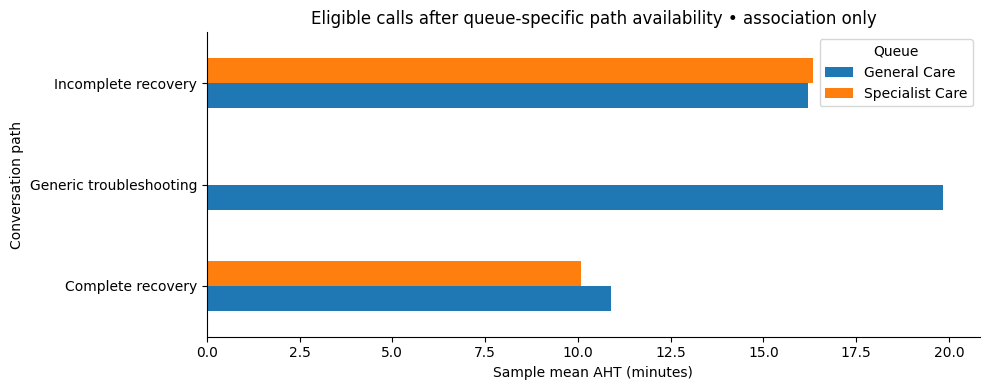

In [6]:
phase = calls.groupby(['Queue','Phase']).apply(recovery_metrics,include_groups=False)
display(phase.round(3))
available = calls[calls['Recovery available']].copy()
recovery = available.groupby('Queue').apply(recovery_metrics,include_groups=False)
display(recovery.round(3))
recovery.to_csv(OUT/'available_period_recovery.csv')
e = available[available['Eligible for recovery'].eq('Yes')]
path = e.groupby(['Queue','Conversation path'])['AHT minutes'].agg(n='size',mean='mean',median='median')
display(path.round(2))
fig,ax=plt.subplots(figsize=(10,4))
path['mean'].unstack(0).plot.barh(ax=ax)
ax.set_xlabel('Sample mean AHT (minutes)');ax.set_title('Eligible calls after queue-specific path availability • association only')
plt.tight_layout();plt.show()


In General Care after September 21, **76/204 eligible sampled calls (37.3%)** completed both transactions; **159/204** recorded a serial check, **89/204** arranged replacement. Thirteen replacement calls lacked Plus. The other 115 eligible calls followed generic troubleshooting. This is a sampled-call result, not an estimate of all eligible demand.

Within that same queue and period, complete recovery averaged **10.89 minutes (n=76)** versus **19.84 (n=115)** for generic troubleshooting. Specialist eligible calls after September 12 completed both in **163/193 (84.5%)**. These are promising exemplars, not a controlled comparison: routing, selection, account complexity, Guide experience, and dates differ. A shorter incomplete call is not success. No rollout initiated by Dana's request is documented.


In [7]:
q = D['qa_joined']
f = D['feedback_joined']
display(D['qa']['Selection reason'].value_counts().rename('reviews').to_frame())
qpost=q[q['Recovery available'] & q['Eligible for recovery'].eq('Yes')]
qa_summary=qpost.groupby('Queue').agg(review_n=('QA review ID','size'),
 impact_yes=('Acknowledged practical impact',lambda x:x.eq('Yes').sum()),
 recognized_yes=('Recognized recovery path',lambda x:x.eq('Yes').sum()),
 recap_yes=('Recap complete',lambda x:x.eq('Yes').sum()))
display(qa_summary)
fpost=f[f['Recovery available'] & f['Eligible for recovery'].eq('Yes')]
fb_summary=fpost.groupby(['Queue','Conversation path']).agg(response_n=('Feedback ID','size'),
 mean_score=('Satisfaction score','mean'),satisfied_share=('Satisfied (4 or 5)',lambda x:x.eq('Yes').mean()))
display(fb_summary.round(3))
print('Repeated QA Call IDs:',q['Call ID'].duplicated().sum(),'; repeated feedback Call IDs:',f['Call ID'].duplicated().sum())


,reviews
Selection reason,
Routine quality sample,820
Oversample: long handle time,520
Oversample: WN7 recovery risk,260


,review_n,impact_yes,recognized_yes,recap_yes
Queue,,,,
General Care,75,43,39,47
Specialist Care,79,77,79,62


response_n  mean_score  \
Queue           Conversation path                                 
General Care    Complete recovery                47       4.532   
                Generic troubleshooting          61       1.459   
                Incomplete recovery               4       2.000   
Specialist Care Complete recovery                98       4.592   
                Incomplete recovery              21       2.048   

                                         satisfied_share  
Queue           Conversation path                         
General Care    Complete recovery                    1.0  
                Generic troubleshooting              0.0  
                Incomplete recovery                  0.0  
Specialist Care Complete recovery                    1.0  
                Incomplete recovery                  0.0

Repeated QA Call IDs: 0 ; repeated feedback Call IDs: 0


Selected feedback is consistent with recovery quality: General Care complete-recovery respondents averaged **4.53/5 (n=47)** versus **1.46 (n=61)** following generic troubleshooting. This is not population CSAT or evidence of training impact. QA behavior checklist totals are not validated performance scores. Keep review dates and call dates separate; October 1 reviews/responses can refer to September calls.

## 4. Proposed solution: an actionable recovery cue plus a bounded test
**Immediate learning response:** a ≤5-minute worked example can introduce the pivot from acknowledgment to action, but must link to the current Beacon article. Pair it with branch practice and one observed-call coaching check. Do not teach every Guide every product, force a memorized speech, or reward shorter calls at the expense of recovery.

**One-screen cue — learner-facing draft, subject to Product/Quality review:**
1. **Hear the disruption.** “Losing the whole connection during work calls is disruptive. You said it drops briefly and returns by itself. I can check whether your hub is included in the group we can replace.” Confirm the reported pattern; then model and hub serial. WNM-7 contains a WN7 hub.
2. **Check Orbit, don't guess.** Use BH-4419 / PO-117 and the serial eligibility result. Model alone is not eligibility. If not eligible, continue appropriate troubleshooting/escalation. If serial unavailable or tool down, open eligibility review and give a specific follow-up expectation you can keep; do not invent timing.
3. **Eligible: do both actions.** “Your hub is eligible for a no-cost replacement. We'll also attach twelve months of Plus at no cost as a goodwill benefit. Plus is not a repair for this issue and doesn't prevent every outage.” Verify replacement confirmation and Plus **Applied**. Keep satellite nodes unless separately diagnosed. Do not require repeated restarts before the approved remedy.
4. **Close the loop accurately.** Recap confirmation, shipping estimate shown in Orbit (normally five–seven business days), Plus status, and next steps. Document confirmation/status/follow-up. “The replacement is confirmed; the Plus credit is still pending. Your recovery case remains open, and [specific owner/follow-up expectation confirmed in the tool].” Bracketed text must be filled with a real commitment, never read as a promise without verification. Use unresolved recovery follow-up when either transaction fails; do not report full completion.

**Practice prompts and answer check:**
- Eligible customer has already restarted three times: acknowledge work interruption, check serial once, explain both benefits, verify both transactions, recap; no new restart condition.
- WN7 serial is not eligible: no replacement/free-year promise; diagnose/escalate the actual issue.
- Order confirmed, credit pending: do not call recovery complete; keep case open, record both statuses and arrange specific follow-up.
- Serial absent or eligibility tool unavailable: eligibility review and clear follow-up, no guessed entitlement.

Team Lead checks the observable branch and transaction status, gives one specific correction, and has the Guide retry. Attendance and quiz completion track reach, not transfer to the call.

## 5. Ownership, capacity, and decision rules — proposals, not completed actions
| Owner | Next step | Evidence before expansion |
|---|---|---|
| Dana / Priya | Sponsor 24-General-Care-Guide pilot across shifts and tenure groups; match comparison shifts or randomize small cohorts if practical | Roster, exposure dates, comparable call mix, baseline reviews |
| Learning + Mateo | ≤5-minute model, one-screen cue, 7-minute branch practice | 12 minutes/Guide; 24 × 12 = **4.8 Guide-hours** total, excluding Lead/QA effort |
| Renee / WFM | Stagger six groups of four outside 11 a.m.–4 p.m. Central, subject to coverage approval | 48 Guide-minutes removed per cohort; model actual queue effect rather than infer from daily averages |
| Product Operations / Knowledge / Systems | Validate offer language; fix customer-language search and older-article cross-link; confirm screen access and unresolved follow-up | Successful retrieval and transaction walkthrough from General Care workstation; no assumed sandbox |
| Priya / Team Leads + Elias / Quality | One coached call per participating Guide within a week; focused reviews across both groups, including ineligible and failed-transaction cases | Recognition, serial result followed, two transactions or honest unresolved handoff, clear recap; no new punitive score |
| Jules + Product/Legal | Own proactive notice timing and audience | Notice remains in review as of October 1; annotate actual release if it occurs |

**Test plan:** proposed two-week staggered test; collect a one-week pre-period where the General article is already available and compare contemporaneous eligible calls within General Care. If randomization is impractical, report descriptive changes with strata for shift, tenure, mix, and staffing. Log simultaneous article/search/routing changes; do not isolate a training effect from a bundled test.

**Proposed gates requiring owner agreement:** 100% safe branch selection in practice before unsupervised use; no unsupported offer in reviewed ineligible calls; eligible sample completion improves ≥15 percentage points over comparable baseline with denominator ≥30 per group; no >2-point abandonment or >0.5-minute wait deterioration in matched operating windows. These are operational starting proposals, not statistically validated thresholds. Small/biased samples yield an inconclusive result, not success. Review transaction failures separately from Guide behavior.

If completion improves but queues worsen, revise capacity/cohort scheduling before expansion. If serial checking improves but Plus failures persist, prioritize Systems follow-up rather than repeat empathy training. Specialist capacity is limited (about 70 extra contacts/day temporarily per September 19 notes); blanket transfers and an automated offer lack approval and are not recommended as an immediate substitute.

**Limits and next data needed:** no household/account IDs to measure repeat contacts, no order/credit event ledger to verify final fulfillment or backlog age, no exposure/roster/tenure file, no reliable wait numerator or interval-level staffing. Request those internally before claiming repeat-contact reduction, causal impact, closed recovery backlog, or sustainable capacity. Sample incomplete calls exported by monitoring are review candidates, not a deduplicated household backlog.

## Source traceability
- `DATA_DICTIONARY.md`: populations, duplicates, bias, retrospective eligibility, chronology.
- `Orbit_operations.xlsx`: Daily operations and Staffing for population metrics; Call sample for paths and duration; Product catalog for code checks.
- `Quality_and_feedback.xlsx`: selected reviews and voluntary responses; joined on Call ID with cardinality checks.
- `Case_info.md`: BH-2240 vs BH-4419, PO-117 approved recovery, CLEAR, product limits.
- `threads.md`, “Guide reference follow-up,” September 28: distribution versus readership.
- `meetings.md`: August 31 confirmation; September 10 approval; September 16 calibration; September 18 Guide feedback; September 19 workforce; September 21 release; September 24 open items; October 1 leadership discussion.
- Dana's September 29 email frames urgency and original short-video request. `00_START_HERE.md` establishes fictional scope and case date. `INTERVIEW_PREP_PROMPT.md` adds no empirical case facts.
